# Experimentos de ventanas temporales, dimensiones latentes y t-SNE

Este notebook estudia de forma controlada tres decisiones del modelo CPC-GRU aplicado a las variables MVNX:

1. La duración de la ventana de entrada y el horizonte de predicción CPC.
2. La dimensión de los vectores locales $z_t$ y contextuales $c_t$.
3. La forma de resumir la secuencia $C=(c_1,\ldots,c_T)$ para clasificar la actividad.

También incluye una sección para visualizar con **t-SNE** las representaciones $z_T$ y $c_T$ aprendidas por una ronda ya entrenada. Las celdas se entregan sin ejecutar; los resultados se guardan por configuración y ronda para poder reanudar una corrida interrumpida.

## 1. Diseño experimental

La entrada actual del proyecto tiene 4 s a 12 Hz, por lo que produce 48 vectores $z_t$ y 48 vectores $c_t$. La arquitectura base usa $\dim(z_t)=128$, $\dim(c_t)=256$ y predice 12 pasos futuros (1 s).

Los experimentos se separan en etapas para no confundir sus efectos:

- **temporal:** cambia la duración de la ventana y el horizonte CPC, conservando las dimensiones actuales.
- **dimensiones:** cambia $\dim(z_t)$ y $\dim(c_t)$ usando la mejor configuración temporal elegida previamente.
- **pooling:** compara $c_T$, la media temporal y resúmenes del último segundo.
- **confirmación:** repite solamente las configuraciones finalistas con tres semillas.

Cada configuración se evalúa con LOSO sobre los sujetos 1–12. En cada ronda, un sujeto se evalúa, el siguiente se usa como validación interna y los diez restantes entrenan. Los sujetos 13 y 14 no se cargan ni se utilizan.

In [3]:
import copy
import json
import os
import re
import time
from dataclasses import asdict, dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Semillas y protocolo general.
SEED = 0
TARGET_FS = 12
CV_SUBJECTS = tuple(range(1, 13))
TEST_SUBJECTS = (13, 14)  # Se mantienen cerrados.
SUP_HOP = 6              # Una ventana supervisada cada 0.5 s.
CPC_HOP = 24             # Una ventana CPC cada 2 s para estimar pasos/época.
SCALER_FIT_POINTS = 250_000
PROBE_TRAIN_MAX = 15_000

# Etapa a ejecutar: temporal, dimensiones, pooling, confirmacion o todas.
STAGE = os.environ.get('NB13_STAGE', 'temporal')
QUICK = os.environ.get('NB13_QUICK') == '1'
RUN_EXPERIMENTS = True

# Por defecto se usa el subconjunto mínimo encontrado en el notebook 11.
# Cambiar a 'full_30' permite repetir el estudio con las 30 variables.
FEATURE_MODE = 'minimal_10'  # minimal_10 | full_30

# Valores que se actualizan manualmente después de revisar cada etapa.
BEST_WINDOW_SECONDS = 4.0
BEST_HORIZON_SECONDS = 1.0
BEST_Z_DIM = 128
BEST_C_DIM = 256
BEST_POOLING = 'last'
CPC_SELECTION_POOLING = 'last'  # Mantiene fijo el criterio de parada de CPC al comparar pooling.

# Entrenamiento equivalente al CPC-GRU LP-FT de los notebooks 10–12.
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
LP_EPOCHS, LP_PATIENCE, LP_LR = 20, 3, 1e-3
FT_EPOCHS, FT_PATIENCE = 30, 5
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
FT_TRAIN_CAP = STEPS_CAP = None

FOLDS = CV_SUBJECTS
if QUICK:
    # Corrida corta para validar el flujo antes de iniciar el barrido completo.
    FOLDS = (1, 2)
    CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 2, 1, 1
    LP_EPOCHS, FT_EPOCHS, FT_PATIENCE = 1, 1, 1
    PROBE_TRAIN_MAX, FT_TRAIN_CAP, STEPS_CAP = 2_000, 2_000, 5

if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
SYNC_DIR = REPO_DIR / 'notebooks' / '_cache' / 'sync' / f'fs{TARGET_FS}'
RECOVER_DIR = REPO_DIR / 'notebooks' / '_cache' / 'sync' / f'fs{TARGET_FS}_mvnx_recuperados'
RUN_DIR = REPO_DIR / 'checkpoints' / (f'nb13_ventanas_latentes_tsne_fs{TARGET_FS}' + ('_quick' if QUICK else ''))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / 'progreso.log'

assert (SYNC_DIR / 'metadata.json').exists(), (
    f'Falta {SYNC_DIR}. Ejecuta primero 07_Sincronizacion_sEMG_MVNX.ipynb.'
)
SYNC_META = json.loads((SYNC_DIR / 'metadata.json').read_text())
LABELS, NO_LABEL = SYNC_META['label_order'], SYNC_META['sin_etiqueta']

def log(message):
    line = f'{datetime.now():%Y-%m-%d %H:%M} | {message}'
    print(line)
    with open(LOG_FILE, 'a') as fh:
        fh.write(line + '\n')

print(f'PyTorch {torch.__version__} | dispositivo: {DEVICE} | etapa: {STAGE} | QUICK: {QUICK}')
print(f'Resultados: {RUN_DIR.relative_to(REPO_DIR)}')

PyTorch 2.11.0 | dispositivo: mps | etapa: temporal | QUICK: False
Resultados: checkpoints/nb13_ventanas_latentes_tsne_fs12


## 2. Carga y selección de variables

Se reutiliza la exportación sincronizada a 12 Hz producida por el notebook 07. A partir de las columnas MVNX se calculan las mismas 30 variables físicas de los notebooks 10–12.

El modo `minimal_10` conserva codos, muñecas, caderas, rodillas y rapidez de ambas manos. El notebook 11 mostró que este subconjunto contiene prácticamente la misma información que las 30 variables y requiere 11 sensores.

> **Alcance de esta reducción:** aquí la rapidez de las manos todavía proviene del modelo Xsens. Para reproducir estrictamente un sistema independiente de 11 IMU debe sustituirse por la aceleración de las manos calculada en el notebook 12. Por ello, este experimento estudia primero la reducción de información y de costo computacional, no una nueva validación del hardware.

In [4]:
# Columnas necesarias para derivar las 30 variables físicamente interpretables.
RAW_COLUMNS = (
    [f'position__{s}__{a}' for s in ('Pelvis', 'Head', 'LeftHand', 'RightHand') for a in 'xyz']
    + [f'velocity__{s}__{a}' for s in ('Pelvis', 'LeftHand', 'RightHand') for a in 'xyz']
    + [f'angularVelocity__{s}__{a}' for s in ('Pelvis', 'T8') for a in 'xyz']
    + [f'jointAngle__{j}__c3' for j in (
        'jL5S1', 'jC1Head', 'jLeftElbow', 'jRightElbow', 'jLeftWrist', 'jRightWrist',
        'jLeftHip', 'jRightHip', 'jLeftKnee', 'jRightKnee')]
    + [f'jointAngleXZY__{j}__{c}' for j in ('jLeftShoulder', 'jRightShoulder') for c in ('c1', 'c3')]
    + [f'footContacts__{f}_{p}' for f in ('LeftFoot', 'RightFoot') for p in ('Heel', 'Toe')]
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}
SIDES = (('izq', 'Left'), ('der', 'Right'))

def derive(raw):
    """Convierte columnas MVNX crudas en las 30 variables utilizadas por el proyecto."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    out = {
        'tronco_flexion': col('jointAngle__jL5S1__c3'),
        'cuello_flexion': col('jointAngle__jC1Head__c3'),
    }
    for lado, side in SIDES:
        out[f'{lado}_hombro_flexion'] = col(f'jointAngleXZY__j{side}Shoulder__c3')
        out[f'{lado}_hombro_abduccion'] = col(f'jointAngleXZY__j{side}Shoulder__c1')
        out[f'{lado}_codo_flexion'] = col(f'jointAngle__j{side}Elbow__c3')
        out[f'{lado}_muneca_flexion'] = col(f'jointAngle__j{side}Wrist__c3')
        out[f'{lado}_cadera_flexion'] = col(f'jointAngle__j{side}Hip__c3')
        out[f'{lado}_rodilla_flexion'] = col(f'jointAngle__j{side}Knee__c3')
    out['pelvis_altura'] = col('position__Pelvis__z')
    out['cabeza_altura'] = col('position__Head__z')
    for lado, side in SIDES:
        out[f'{lado}_mano_altura'] = col(f'position__{side}Hand__z')
        out[f'{lado}_mano_alcance'] = np.hypot(
            col(f'position__{side}Hand__x') - col('position__Pelvis__x'),
            col(f'position__{side}Hand__y') - col('position__Pelvis__y'))
    out['pelvis_vel_horizontal'] = np.hypot(col('velocity__Pelvis__x'), col('velocity__Pelvis__y'))
    out['pelvis_vel_vertical'] = col('velocity__Pelvis__z')
    for lado, side in SIDES:
        out[f'{lado}_mano_rapidez'] = np.linalg.norm(
            [col(f'velocity__{side}Hand__{a}') for a in 'xyz'], axis=0)
    out['pelvis_giro'] = np.abs(col('angularVelocity__Pelvis__z'))
    out['tronco_vel_angular'] = np.linalg.norm(
        [col(f'angularVelocity__T8__{a}') for a in 'xyz'], axis=0)
    for lado, side in SIDES:
        out[f'{lado}_talon'] = col(f'footContacts__{side}Foot_Heel')
        out[f'{lado}_punta'] = col(f'footContacts__{side}Foot_Toe')
    return np.column_stack(list(out.values())).astype(np.float32), list(out)

def feature_unit(name):
    if name.endswith(('flexion', 'abduccion')):
        return '°'
    if name.endswith(('altura', 'alcance')):
        return 'm'
    if name.endswith(('vel_horizontal', 'vel_vertical', 'rapidez')):
        return 'm/s'
    if name.endswith(('giro', 'vel_angular')):
        return 'rad/s'
    return '0/1'

In [5]:
# Se concatenan los ensayos sin permitir que una ventana cruce sus límites.
rows, signal_parts, label_parts, offsets = [], [], [], [0]
for conjunto in ('un_brazo', 'bimanual'):
    base = SYNC_DIR / conjunto
    names = [c['name'] for c in json.loads((base / 'columns.json').read_text())['mvnx']]
    pos = {name: i for i, name in enumerate(names)}
    with np.load(base / 'series.npz') as data:
        mvnx = data['mvnx'][:, [pos[c] for c in RAW_COLUMNS]]
        label_mvnx = data['label_mvnx']
    for trial in pd.read_csv(base / 'trials.csv').itertuples(index=False):
        # Los sujetos 13 y 14 se omiten desde la carga, no sólo al construir ventanas.
        if trial.subject not in CV_SUBJECTS:
            continue
        sl = slice(trial.offset, trial.offset + trial.n_steps)
        derived, FEATURES_30 = derive(mvnx[sl])
        rows.append({
            'trial_idx': len(rows), 'mvnx_file': trial.mvnx_file, 'conjunto': conjunto,
            'subject': trial.subject, 'offset': offsets[-1], 'n_steps': trial.n_steps,
            'recuperado': False,
        })
        signal_parts.append(derived)
        label_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + trial.n_steps)
    del mvnx, label_mvnx

# Si el notebook 11 o 12 ya creó la caché de los tres ensayos recuperados, se agregan.
# La ausencia de esta caché no impide probar el código, pero debe declararse al comparar cifras.
if RECOVER_DIR.exists():
    for path in sorted(RECOVER_DIR.glob('Subj_*.npz')):
        subject_match = re.match(r'Subj_(\d+)', path.name)
        subject = int(subject_match.group(1))
        if subject not in CV_SUBJECTS:
            continue
        with np.load(path) as data:
            derived, FEATURES_30 = derive(data['mvnx'])
            lab = data['label_mvnx'].astype(np.int64)
        rows.append({
            'trial_idx': len(rows), 'mvnx_file': path.with_suffix('.mvnx').name,
            'conjunto': 'bimanual', 'subject': subject, 'offset': offsets[-1],
            'n_steps': len(derived), 'recuperado': True,
        })
        signal_parts.append(derived)
        label_parts.append(lab)
        offsets.append(offsets[-1] + len(derived))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])
signals_30 = np.concatenate(signal_parts).astype(np.float32)
labels_series = np.concatenate(label_parts).astype(np.int64)
del signal_parts, label_parts

MINIMAL_VARIABLES = [
    'izq_codo_flexion', 'izq_muneca_flexion', 'izq_cadera_flexion', 'izq_rodilla_flexion',
    'der_codo_flexion', 'der_muneca_flexion', 'der_cadera_flexion', 'der_rodilla_flexion',
    'izq_mano_rapidez', 'der_mano_rapidez',
]
SELECTED_FEATURES = MINIMAL_VARIABLES if FEATURE_MODE == 'minimal_10' else FEATURES_30
selected_cols = [FEATURES_30.index(name) for name in SELECTED_FEATURES]
signals_raw = np.ascontiguousarray(signals_30[:, selected_cols])
CHANNELS, N_CH = list(SELECTED_FEATURES), len(SELECTED_FEATURES)
BINARY = [i for i, name in enumerate(CHANNELS) if feature_unit(name) == '0/1']

assert not set(trials['subject']) & set(TEST_SUBJECTS)
assert not np.isnan(signals_raw).any() and trials['mvnx_file'].is_unique
print(f'{len(trials)} ensayos | {len(signals_raw):,} instantes | {N_CH} variables ({FEATURE_MODE})')
print(f'Ensayos recuperados incluidos: {int(trials.recuperado.sum())}')
display(pd.DataFrame({'variable': CHANNELS, 'unidad': [feature_unit(v) for v in CHANNELS]}))

434 ensayos | 288,953 instantes | 10 variables (minimal_10)
Ensayos recuperados incluidos: 0


,variable,unidad
0,izq_codo_flexion,°
1,izq_muneca_flexion,°
2,izq_cadera_flexion,°
3,izq_rodilla_flexion,°
4,der_codo_flexion,°
5,der_muneca_flexion,°
6,der_cadera_flexion,°
7,der_rodilla_flexion,°
8,izq_mano_rapidez,m/s
9,der_mano_rapidez,m/s


## 3. Configuraciones que se compararán

El barrido temporal usa ventanas de 2, 4 y 6 s. Un horizonte sólo se incluye cuando cabe dentro de la ventana y deja contextos válidos para InfoNCE.

El barrido de dimensiones conserva tres convoluciones, pero cambia el número de canales de la última convolución ($z_t$) y el estado oculto de la GRU ($c_t$). El barrido de `pooling` no cambia CPC: únicamente cambia qué resumen de $C$ recibe la cabeza supervisada.

In [6]:
@dataclass(frozen=True)
class Experiment:
    name: str
    window_seconds: float
    horizon_seconds: float
    z_dim: int
    c_dim: int
    pooling: str = 'last'

    @property
    def win(self):
        return int(round(self.window_seconds * TARGET_FS))

    @property
    def horizons(self):
        return tuple(range(1, int(round(self.horizon_seconds * TARGET_FS)) + 1))

def temporal_experiments():
    out = []
    for window_s in (2.0, 4.0, 6.0):
        for horizon_s in (0.5, 1.0, 2.0):
            # Se exige al menos medio segundo de contexto antes del mayor futuro.
            if int(window_s * TARGET_FS) - int(horizon_s * TARGET_FS) > TARGET_FS // 2:
                out.append(Experiment(
                    f't{window_s:g}s_h{horizon_s:g}s', window_s, horizon_s, 128, 256, 'last'))
    return out

def dimension_experiments():
    pairs = ((64, 128), (64, 256), (128, 128), (128, 256), (128, 512), (256, 256), (256, 512))
    return [Experiment(
        f'z{z}_c{c}', BEST_WINDOW_SECONDS, BEST_HORIZON_SECONDS, z, c, BEST_POOLING)
        for z, c in pairs]

def pooling_experiments():
    methods = ('last', 'mean_all', 'mean_last_second', 'last_plus_mean_last_second')
    return [Experiment(
        f'pool_{method}', BEST_WINDOW_SECONDS, BEST_HORIZON_SECONDS, BEST_Z_DIM, BEST_C_DIM, method)
        for method in methods]

if STAGE == 'temporal':
    EXPERIMENTS, SEEDS = temporal_experiments(), (SEED,)
elif STAGE == 'dimensiones':
    EXPERIMENTS, SEEDS = dimension_experiments(), (SEED,)
elif STAGE == 'pooling':
    EXPERIMENTS, SEEDS = pooling_experiments(), (SEED,)
elif STAGE == 'confirmacion':
    # Editar esta lista después de elegir finalistas sin consultar a los sujetos 13–14.
    EXPERIMENTS = [Experiment(
        'final', BEST_WINDOW_SECONDS, BEST_HORIZON_SECONDS, BEST_Z_DIM, BEST_C_DIM, BEST_POOLING)]
    SEEDS = (0, 1, 2)
elif STAGE == 'todas':
    candidates = temporal_experiments() + dimension_experiments() + pooling_experiments()
    EXPERIMENTS = list({e.name: e for e in candidates}.values())
    SEEDS = (SEED,)
else:
    raise ValueError(f'Etapa desconocida: {STAGE}')

display(pd.DataFrame([asdict(e) | {'pasos': e.win, 'K': len(e.horizons)} for e in EXPERIMENTS]))

,name,window_seconds,horizon_seconds,z_dim,c_dim,pooling,pasos,K
0,t2s_h0.5s,2.0,0.5,128,256,last,24,6
1,t2s_h1s,2.0,1.0,128,256,last,24,12
2,t4s_h0.5s,4.0,0.5,128,256,last,48,6
3,t4s_h1s,4.0,1.0,128,256,last,48,12
4,t4s_h2s,4.0,2.0,128,256,last,48,24
5,t6s_h0.5s,6.0,0.5,128,256,last,72,6
6,t6s_h1s,6.0,1.0,128,256,last,72,12
7,t6s_h2s,6.0,2.0,128,256,last,72,24


## 4. Ventanas, particiones y escalado

Las ventanas se reconstruyen para cada duración. No se copian previamente todas las ventanas: se guardan sus índices y se materializan por lote en el dispositivo. La etiqueta supervisada corresponde siempre al último instante.

El escalador robusto se ajusta en cada ronda solamente con los diez sujetos de entrenamiento. El sujeto de validación interna y el sujeto evaluado no participan en los cuantiles.

In [7]:
def build_indices(win):
    """Construye índices CPC y supervisados para una duración de ventana concreta."""
    sup, cpc = [], []
    for trial in trials.itertuples():
        if trial.n_steps < win:
            continue
        lab = labels_series[trial.offset:trial.offset + trial.n_steps]
        cpc += [(trial.trial_idx, trial.subject, start)
                for start in range(0, trial.n_steps - win + 1, CPC_HOP)]
        ends = np.arange(win - 1, trial.n_steps, SUP_HOP)
        sup += [(trial.trial_idx, trial.subject, end - win + 1, end, lab[end])
                for end in ends[lab[ends] != NO_LABEL]]
    return (
        pd.DataFrame(sup, columns=['trial_idx', 'subject', 'start_step', 'end_step', 'target']),
        pd.DataFrame(cpc, columns=['trial_idx', 'subject', 'start_step']),
    )

def starts_of(frame):
    return offsets[frame['trial_idx'].to_numpy()] + frame['start_step'].to_numpy()

def inner_validation_subject(held_out):
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]

def split_subjects(held_out):
    inner_val = inner_validation_subject(held_out)
    train_subjects = tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))
    return inner_val, train_subjects

def fit_scaler(train_subjects, seed=SEED):
    """Clip q0.1–q99.9 y escalado por (q95-q5), ajustado sólo en entrenamiento."""
    selected_trials = trials[trials['subject'].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in selected_trials.itertuples()])
    rng = np.random.default_rng(seed)
    sample = signals_raw[rng.choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, [0.001, 0.999], axis=0)
    clipped = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(clipped, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    if BINARY:
        lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {key: value.astype(np.float32) for key, value in {
        'lower': lower, 'upper': upper, 'center': center, 'scale': scale}.items()}

def apply_scaler(params):
    return ((np.clip(signals_raw, params['lower'], params['upper']) - params['center']) / params['scale']).astype(np.float32)

def eval_set(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby('target', group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {'index': frame.index.to_numpy(), 'starts': starts_of(frame), 'y': frame['target'].to_numpy()}

## 5. Modelo CPC-GRU parametrizable

El encoder causal genera un vector $z_t$ por instante. La GRU recorre la secuencia y produce $c_t$. Durante CPC, una matriz $W_k$ utiliza $c_t$ para reconocer el futuro correcto $z_{t+k}$ entre los demás elementos del lote.

El relleno de las convoluciones se aplica sólo a la izquierda, de modo que ni $z_t$ ni $c_t$ pueden consultar el futuro.

In [8]:
@dataclass
class CPCConfig:
    n_channels: int
    z_dim: int
    c_dim: int
    horizons: tuple
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS

    @property
    def enc_channels(self):
        # Las dos primeras capas se mantienen; la última define dim(z_t).
        return (32, 64, self.z_dim)

class CausalEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.left_pad = cfg.enc_kernel_size - 1
        channels_in = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([
            nn.Conv1d(cin, cout, cfg.enc_kernel_size)
            for cin, cout in zip(channels_in, cfg.enc_channels)
        ])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z

class CPCModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(
            cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers,
            dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([
            nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        # z y c quedan como (lote, tiempo, dimensión).
        z = self.encoder(x).transpose(1, 2)
        c = self.ar(z)[0]
        return z, c

    def info_nce(self, x):
        z, c = self.encode(x)
        lo = max(1, z.shape[1] // 8)
        hi = z.shape[1] - max(self.cfg.horizons)
        if hi <= lo:
            raise ValueError('La ventana es demasiado corta para el horizonte CPC elegido.')
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].T
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()

def pool_context(c, method):
    """Reduce la secuencia C a un vector para la clasificación supervisada."""
    if method == 'last':
        return c[:, -1]
    if method == 'mean_all':
        return c.mean(dim=1)
    if method == 'mean_last_second':
        return c[:, -min(TARGET_FS, c.shape[1]):].mean(dim=1)
    if method == 'last_plus_mean_last_second':
        tail = c[:, -min(TARGET_FS, c.shape[1]):].mean(dim=1)
        return torch.cat([c[:, -1], tail], dim=1)
    raise ValueError(f'Pooling desconocido: {method}')

class CPCClassifier(nn.Module):
    def __init__(self, cpc_model, pooling, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        self.pooling = pooling
        dim = cpc_model.cfg.c_dim * (2 if pooling == 'last_plus_mean_last_second' else 1)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def sequences(self, x):
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def features(self, x):
        return pool_context(self.sequences(x)[1], self.pooling)

    def forward(self, x):
        return self.head(self.features(x))

## 6. Entrenamiento de una ronda LOSO

Cada ronda realiza tres pasos:

1. Preentrenamiento CPC sin etiquetas, con negativos del mismo sujeto.
2. `LP`: entrenamiento de la cabeza con el encoder y la GRU congelados.
3. `FT`: ajuste fino de toda la red, con una tasa menor para el backbone.

La parada temprana de CPC utiliza una sonda lineal en el sujeto de validación interna. El sujeto evaluado se consulta una sola vez, al terminar la ronda.

In [9]:
S_T = WIN_RANGE = None

def get_windows(starts):
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)

@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[i:i + batch])) for i in range(0, len(starts), batch)])

@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()

def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(
        counts.sum() / (len(LABELS) * np.maximum(counts, 1)),
        dtype=torch.float32, device=DEVICE)

def prepare_round(exp, held_out):
    global S_T, WIN_RANGE
    sup_index, cpc_index = build_indices(exp.win)
    sup_cv = sup_index[sup_index['subject'].isin(CV_SUBJECTS)]
    cpc_cv = cpc_index[cpc_index['subject'].isin(CV_SUBJECTS)]
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv['subject'].isin(train_subjects)]
    sets = {
        'probe_train': eval_set(train, PROBE_TRAIN_MAX),
        'ft_train': eval_set(train, FT_TRAIN_CAP),
        'val': eval_set(sup_cv[sup_cv['subject'] == inner_val]),
        'held': eval_set(sup_cv[sup_cv['subject'] == held_out]),
    }
    n_steps = max(1, len(cpc_cv[cpc_cv['subject'].isin(train_subjects)]) // CPC_BATCH)
    if STEPS_CAP:
        n_steps = min(n_steps, STEPS_CAP)
    scaler = fit_scaler(train_subjects)
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler).T)).to(DEVICE)
    WIN_RANGE = torch.arange(exp.win, device=DEVICE)
    return {
        'held_out': held_out, 'inner_val': inner_val, 'train_subjects': train_subjects,
        'sets': sets, 'n_steps': n_steps, 'scaler': scaler,
    }

class SameSubjectSampler:
    def __init__(self, subjects, win, seed):
        self.rng = np.random.default_rng(seed)
        eligible = trials[trials['subject'].isin(subjects) & (trials['n_steps'] >= win)]
        starts = np.concatenate([
            np.arange(r.offset, r.offset + r.n_steps - win + 1) for r in eligible.itertuples()])
        subj = np.concatenate([
            np.full(r.n_steps - win + 1, r.subject) for r in eligible.itertuples()])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        subject = self.rng.choice(list(self.by_subject), p=self.p)
        pool = self.by_subject[subject]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)

def build_cpc(exp, seed):
    torch.manual_seed(seed)
    cfg = CPCConfig(N_CH, exp.z_dim, exp.c_dim, exp.horizons)
    return CPCModel(cfg).to(DEVICE)

def probe_val_f1(model, rnd, pooling):
    model.eval()
    def representations(part):
        return batched(
            lambda x: pool_context(model.encode(x)[1], pooling),
            rnd['sets'][part]['starts']).float().cpu().numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(
        max_iter=3000, class_weight='balanced', random_state=SEED))
    probe.fit(representations('probe_train'), rnd['sets']['probe_train']['y'])
    return f1_score(
        rnd['sets']['val']['y'], probe.predict(representations('val')), average='macro')

def train_cpc(exp, rnd, seed):
    t0 = time.time()
    model = build_cpc(exp, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd['train_subjects'], exp.win, seed)
    best = {'f1': -1.0, 'epoch': 0, 'state': copy.deepcopy(model.state_dict())}
    bad = 0
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(rnd['n_steps']):
            loss = model.info_nce(get_windows(sampler.batch()))
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            # La parada CPC usa siempre c_T. Así, el barrido de pooling no cambia qué época
            # del backbone se elige y la comparación se concentra en el resumen supervisado.
            score = probe_val_f1(model, rnd, CPC_SELECTION_POOLING)
            if score > best['f1'] + 1e-4:
                best = {'f1': score, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
                bad = 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best['state'])
    return model, {'best_epoch': best['epoch'], 'f1_val': best['f1'], 'minutes': (time.time() - t0) / 60}

In [10]:
def linear_probe_head(model, sets, seed):
    """Etapa LP: optimiza sólo la cabeza sobre representaciones congeladas."""
    model.eval()
    X_train = batched(model.features, sets['ft_train']['starts'])
    X_val = batched(model.features, sets['val']['starts'])
    y_train = torch.as_tensor(sets['ft_train']['y'], device=DEVICE)
    weights = class_weights(sets['ft_train']['y'])
    optimizer = torch.optim.AdamW(model.head.parameters(), lr=LP_LR, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best = {'f1': -1.0, 'state': copy.deepcopy(model.head.state_dict())}
    bad = 0
    for _ in range(LP_EPOCHS):
        model.head.train()
        order = rng.permutation(len(y_train))
        for start in range(0, len(order), FINETUNE_BATCH):
            idx = torch.as_tensor(order[start:start + FINETUNE_BATCH], device=DEVICE)
            loss = F.cross_entropy(model.head(X_train[idx]), y_train[idx], weight=weights)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.head.eval()
        with torch.no_grad():
            score = f1_score(
                sets['val']['y'], model.head(X_val).argmax(1).cpu().numpy(), average='macro')
        if score > best['f1'] + 1e-4:
            best, bad = {'f1': score, 'state': copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.head.load_state_dict(best['state'])
    return best['f1']

def finetune(exp, cpc_model, sets, seed):
    """LP-FT: LP es la época 0 y después se actualiza toda la red."""
    t0 = time.time()
    torch.manual_seed(seed)
    model = CPCClassifier(cpc_model, exp.pooling).to(DEVICE)
    best = {
        'f1': linear_probe_head(model, sets, seed), 'epoch': 0,
        'state': copy.deepcopy(model.state_dict()),
    }
    optimizer = torch.optim.AdamW([
        {'params': list(model.encoder.parameters()) + list(model.ar.parameters()),
         'lr': FINETUNE_LR_BACKBONE},
        {'params': model.head.parameters(), 'lr': FINETUNE_LR_HEAD},
    ], weight_decay=1e-4)
    train = sets['ft_train']
    y_all = torch.as_tensor(train['y'], device=DEVICE)
    weights = class_weights(train['y'])
    rng, bad = np.random.default_rng(seed), 0
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train['y']))
        for start in range(0, len(order), FINETUNE_BATCH):
            idx_np = order[start:start + FINETUNE_BATCH]
            idx = torch.as_tensor(idx_np, device=DEVICE)
            logits = model(get_windows(train['starts'][idx_np]))
            loss = F.cross_entropy(logits, y_all[idx], weight=weights)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
        score = f1_score(sets['val']['y'], predict(model, sets['val']['starts']), average='macro')
        if score > best['f1'] + 1e-4:
            best = {'f1': score, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
            bad = 0
        else:
            bad += 1
        if bad >= FT_PATIENCE:
            break
    model.load_state_dict(best['state'])
    return model, {'best_epoch': best['epoch'], 'f1_val': best['f1'], 'minutes': (time.time() - t0) / 60}

def run_round(exp, held_out, seed):
    """Entrena, evalúa y guarda una configuración en una ronda LOSO."""
    folder = RUN_DIR / FEATURE_MODE / exp.name
    folder.mkdir(parents=True, exist_ok=True)
    result_path = folder / f'ronda_s{held_out:02d}_semilla{seed}.json'
    model_path = result_path.with_suffix('.pt')
    if result_path.exists() and model_path.exists():
        return json.loads(result_path.read_text())
    rnd = prepare_round(exp, held_out)
    cpc_model, cpc_info = train_cpc(exp, rnd, seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    model, ft_info = finetune(exp, cpc_model, rnd['sets'], seed)
    y = rnd['sets']['held']['y']
    pred = predict(model, rnd['sets']['held']['starts'])
    result = {
        'experiment': asdict(exp), 'feature_mode': FEATURE_MODE, 'features': CHANNELS,
        'held_out': held_out, 'inner_val': rnd['inner_val'], 'seed': seed,
        'f1': f1_score(y, pred, average='macro'),
        'cpc': cpc_info, 'finetune': ft_info,
        'minutes': cpc_info['minutes'] + ft_info['minutes'],
        'index': rnd['sets']['held']['index'].tolist(),
        'y': y.tolist(), 'pred': pred.tolist(),
    }
    torch.save({
        'experiment': asdict(exp), 'cpc': cpc_state, 'finetuned': model.state_dict(),
        'scaler': {k: v.tolist() for k, v in rnd['scaler'].items()}, 'features': CHANNELS,
    }, model_path)
    result_path.write_text(json.dumps(result))
    log(f'{exp.name} | sujeto {held_out:2d} | semilla {seed} | F1 {result["f1"]:.3f} | {result["minutes"]:.1f} min')
    del cpc_model, model
    return result

## 7. Ejecución del barrido

Antes de una corrida completa se recomienda ejecutar con `NB13_QUICK=1`. Después, ejecutar una etapa a la vez mediante `NB13_STAGE=temporal`, `dimensiones`, `pooling` o `confirmacion`.

Cada resultado se guarda inmediatamente. Volver a ejecutar la celda carga las rondas terminadas y continúa con las faltantes.

In [11]:
results = []
if RUN_EXPERIMENTS:
    for exp in EXPERIMENTS:
        for seed in SEEDS:
            for held_out in FOLDS:
                results.append(run_round(exp, held_out, seed))
else:
    print('RUN_EXPERIMENTS=False: no se inició entrenamiento.')

print(LOG_FILE.read_text() if LOG_FILE.exists() else 'Todavía no hay registro.')

/var/folders/t0/ptnsplnx03764b9bdz_y1pkm0000gn/T/ipykernel_63474/2151052294.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  y_train = torch.as_tensor(sets['ft_train']['y'], device=DEVICE)


2026-11-08 12:56 | t2s_h0.5s | sujeto  1 | semilla 0 | F1 0.873 | 2.2 min
2026-11-08 12:59 | t2s_h0.5s | sujeto  2 | semilla 0 | F1 0.811 | 3.3 min
2026-11-08 13:02 | t2s_h0.5s | sujeto  3 | semilla 0 | F1 0.861 | 2.6 min
2026-11-08 13:06 | t2s_h0.5s | sujeto  4 | semilla 0 | F1 0.881 | 4.8 min
2026-11-08 13:09 | t2s_h0.5s | sujeto  5 | semilla 0 | F1 0.874 | 2.5 min
2026-11-08 13:13 | t2s_h0.5s | sujeto  6 | semilla 0 | F1 0.915 | 3.9 min
2026-11-08 13:15 | t2s_h0.5s | sujeto  7 | semilla 0 | F1 0.874 | 2.5 min
2026-11-08 13:19 | t2s_h0.5s | sujeto  8 | semilla 0 | F1 0.855 | 3.3 min
2026-11-08 13:22 | t2s_h0.5s | sujeto  9 | semilla 0 | F1 0.900 | 3.0 min
2026-11-08 13:26 | t2s_h0.5s | sujeto 10 | semilla 0 | F1 0.888 | 4.8 min
2026-11-08 13:55 | t2s_h0.5s | sujeto 11 | semilla 0 | F1 0.895 | 28.8 min
2026-11-08 14:00 | t2s_h0.5s | sujeto 12 | semilla 0 | F1 0.883 | 4.3 min
2026-11-08 14:02 | t2s_h1s | sujeto  1 | semilla 0 | F1 0.865 | 2.9 min
2026-11-08 14:06 | t2s_h1s | sujeto  2 

## 8. Resumen y comparación de configuraciones

La tabla reporta la media, desviación y peor sujeto. Las configuraciones deben compararse por sujeto y no por ventanas agrupadas. El tiempo ayuda a distinguir una mejora real de una expansión desproporcionada del modelo.

No se debe elegir una configuración por diferencias del orden de 0.01 con una sola semilla. Las finalistas deben pasar a la etapa de confirmación.

,experimento,semilla,F1,desv,peor,minutos_por_ronda,rondas
5,t6s_h0.5s,0,0.885,0.025,0.824,8.8,12
4,t4s_h2s,0,0.882,0.034,0.782,25.6,12
6,t6s_h1s,0,0.882,0.030,0.802,8.2,12
2,t4s_h0.5s,0,0.881,0.025,0.820,7.1,12
1,t2s_h1s,0,0.878,0.029,0.801,3.5,12
3,t4s_h1s,0,0.878,0.024,0.815,8.9,12
0,t2s_h0.5s,0,0.876,0.026,0.811,5.5,12
7,t6s_h2s,0,0.871,0.036,0.786,6.5,12


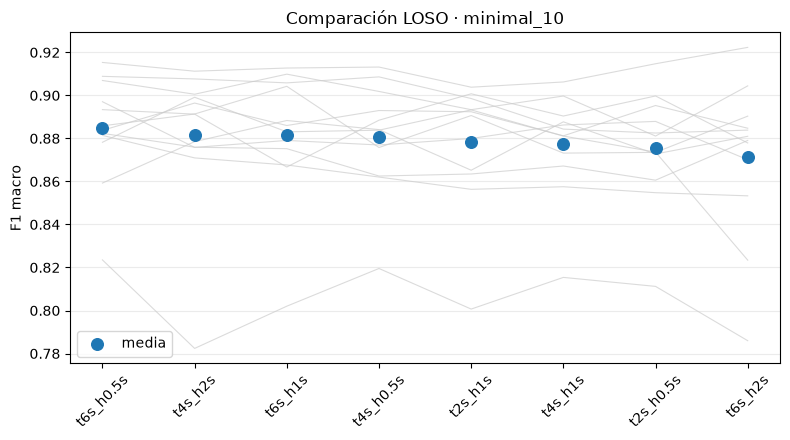

In [12]:
# Se cargan también resultados guardados de ejecuciones anteriores de la etapa actual.
saved = []
base = RUN_DIR / FEATURE_MODE
if base.exists():
    for path in base.glob('*/ronda_s*_semilla*.json'):
        saved.append(json.loads(path.read_text()))
assert saved, 'No hay resultados guardados para resumir.'

detail = pd.DataFrame([{
    'experimento': r['experiment']['name'], 'sujeto': r['held_out'], 'semilla': r['seed'],
    'F1': r['f1'], 'minutos': r['minutes'], **r['experiment'],
} for r in saved])
summary = (detail.groupby(['experimento', 'semilla'], as_index=False)
           .agg(F1=('F1', 'mean'), desv=('F1', 'std'), peor=('F1', 'min'),
                minutos_por_ronda=('minutos', 'mean'), rondas=('sujeto', 'nunique'))
           .sort_values('F1', ascending=False))
display(summary.style.format({
    'F1': '{:.3f}', 'desv': '{:.3f}', 'peor': '{:.3f}', 'minutos_por_ronda': '{:.1f}'}))

# Gráfica general: una línea tenue por sujeto y un punto grande para la media.
order = summary.groupby('experimento')['F1'].mean().sort_values(ascending=False).index.tolist()
means = detail.groupby('experimento')['F1'].mean().reindex(order)
fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(order)), 4.5))
for subject, frame in detail.groupby('sujeto'):
    by_exp = frame.groupby('experimento')['F1'].mean().reindex(order)
    ax.plot(order, by_exp, color='0.8', linewidth=0.8, alpha=0.7)
ax.scatter(order, means, color='#1f77b4', s=70, zorder=3, label='media')
ax.set_ylabel('F1 macro')
ax.set_title(f'Comparación LOSO · {FEATURE_MODE}')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Visualización t-SNE de $z_t$ y $c_t$

La visualización principal utiliza $z_T$ y $c_T$ del último instante porque la etiqueta de la ventana corresponde precisamente a ese instante. Etiquetar todos los pasos intermedios con la actividad final podría crear agrupaciones engañosas.

t-SNE se ajusta por separado para $Z$ y $C$; sus coordenadas no son comparables entre paneles. El objetivo es observar si el contexto $c_T$ separa mejor las actividades que la representación local $z_T$. La geometría global y las distancias entre grupos no deben interpretarse literalmente.

La segunda figura, opcional, toma todos los pasos de unas pocas ventanas y colorea por posición temporal, no por actividad. Sirve para observar cómo evoluciona una trayectoria desde $z_t$ hacia $c_t$.

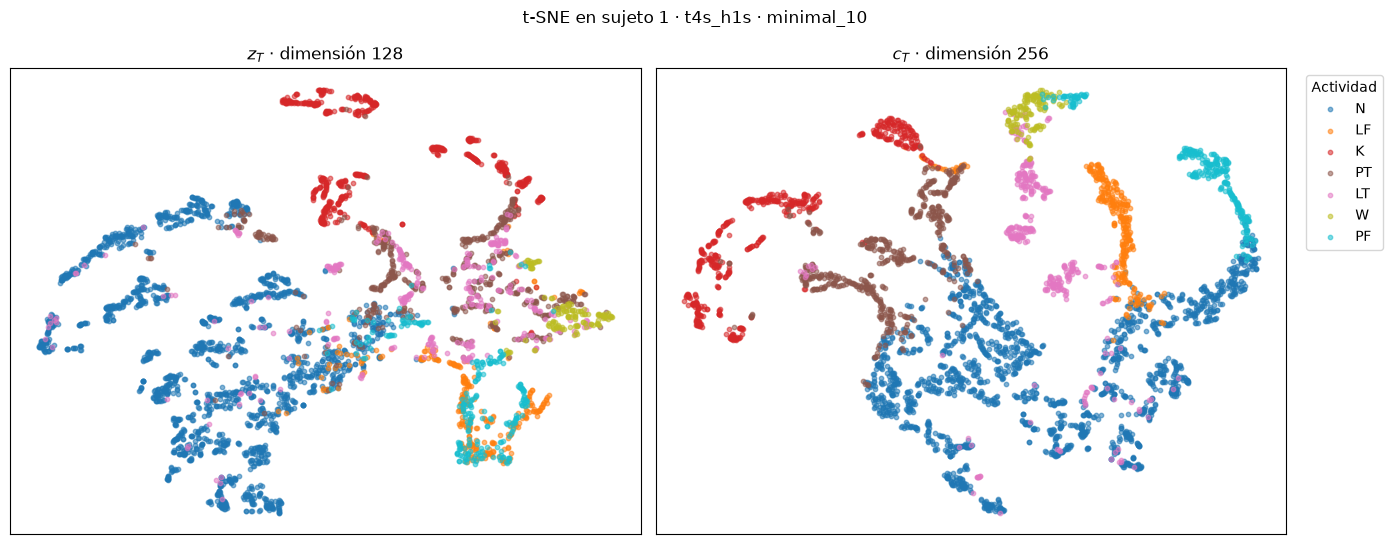

In [13]:
# Elegir una ronda ya terminada. Por defecto se usa la configuración base si está disponible.
TSNE_EXPERIMENT = os.environ.get('NB13_TSNE_EXPERIMENT', 't4s_h1s')
TSNE_SUBJECT = int(os.environ.get('NB13_TSNE_SUBJECT', '1'))
TSNE_SEED = int(os.environ.get('NB13_TSNE_SEED', '0'))
TSNE_MAX_POINTS = 5_000
TSNE_PERPLEXITY = 30

model_path = (RUN_DIR / FEATURE_MODE / TSNE_EXPERIMENT /
              f'ronda_s{TSNE_SUBJECT:02d}_semilla{TSNE_SEED}.pt')
assert model_path.exists(), f'No existe {model_path}. Entrena primero esa ronda.'
saved_model = torch.load(model_path, map_location=DEVICE, weights_only=False)
exp = Experiment(**saved_model['experiment'])
rnd = prepare_round(exp, TSNE_SUBJECT)
cpc = build_cpc(exp, TSNE_SEED)
model = CPCClassifier(cpc, exp.pooling).to(DEVICE)
model.load_state_dict(saved_model['finetuned'])
model.eval()

held = rnd['sets']['held']
rng = np.random.default_rng(SEED)
chosen = np.arange(len(held['y']))
if len(chosen) > TSNE_MAX_POINTS:
    # Muestreo estratificado aproximado para conservar las actividades minoritarias.
    frame = pd.DataFrame({'row': chosen, 'target': held['y']})
    chosen = (frame.groupby('target', group_keys=False)
              .sample(n=max(1, TSNE_MAX_POINTS // len(LABELS)), random_state=SEED)['row']
              .to_numpy())
starts = held['starts'][chosen]
y = held['y'][chosen]

@torch.no_grad()
def endpoint_representations(starts, batch=512):
    z_parts, c_parts = [], []
    for i in range(0, len(starts), batch):
        z, c = model.sequences(get_windows(starts[i:i + batch]))
        z_parts.append(z[:, -1].cpu().numpy())
        c_parts.append(c[:, -1].cpu().numpy())
    return np.concatenate(z_parts), np.concatenate(c_parts)

z_last, c_last = endpoint_representations(starts)

def tsne_embedding(values, seed=SEED):
    # Estandarizar evita que unas dimensiones dominen sólo por su escala.
    values = StandardScaler().fit_transform(values)
    perplexity = min(TSNE_PERPLEXITY, max(5, (len(values) - 1) // 3))
    return TSNE(
        n_components=2, perplexity=perplexity, init='pca', learning_rate='auto',
        max_iter=1_000, random_state=seed).fit_transform(values)

emb_z, emb_c = tsne_embedding(z_last), tsne_embedding(c_last)
colors = plt.cm.tab10(np.linspace(0, 1, len(LABELS)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, emb, title in zip(axes, (emb_z, emb_c),
                          (f'$z_T$ · dimensión {exp.z_dim}', f'$c_T$ · dimensión {exp.c_dim}')):
    for class_id, label in enumerate(LABELS):
        mask = y == class_id
        ax.scatter(emb[mask, 0], emb[mask, 1], s=10, alpha=0.55,
                   color=colors[class_id], label=label)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(title='Actividad', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.suptitle(f't-SNE en sujeto {TSNE_SUBJECT} · {TSNE_EXPERIMENT} · {FEATURE_MODE}')
plt.tight_layout()
plt.show()

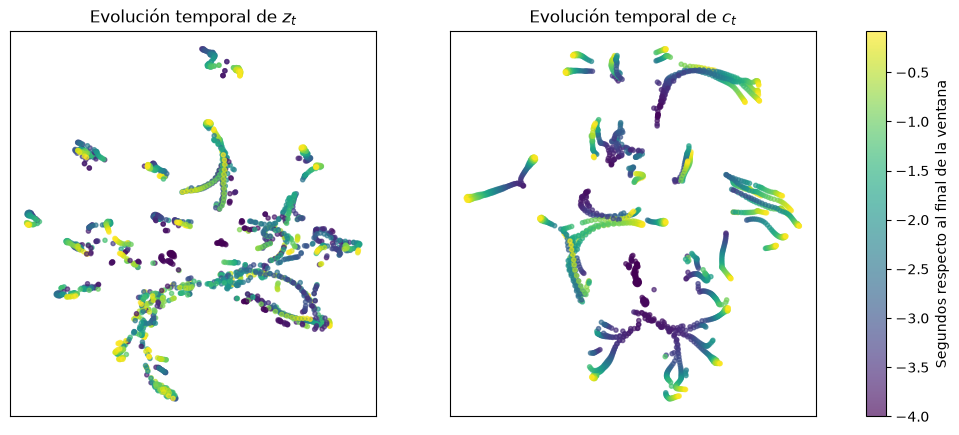

In [14]:
# Visualización opcional de la evolución temporal dentro de pocas ventanas.
N_TRAJECTORY_WINDOWS = 40
trajectory_rows = rng.choice(len(starts), min(N_TRAJECTORY_WINDOWS, len(starts)), replace=False)
with torch.no_grad():
    z_seq, c_seq = model.sequences(get_windows(starts[trajectory_rows]))
z_seq = z_seq.cpu().numpy()
c_seq = c_seq.cpu().numpy()
relative_time = np.tile(np.arange(exp.win) / TARGET_FS - exp.window_seconds, len(z_seq))
emb_z_time = tsne_embedding(z_seq.reshape(-1, exp.z_dim), seed=SEED + 1)
emb_c_time = tsne_embedding(c_seq.reshape(-1, exp.c_dim), seed=SEED + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, emb, title in zip(axes, (emb_z_time, emb_c_time), ('$z_t$', '$c_t$')):
    scatter = ax.scatter(emb[:, 0], emb[:, 1], c=relative_time, cmap='viridis', s=9, alpha=0.65)
    ax.set_title(f'Evolución temporal de {title}')
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(scatter, ax=axes, label='Segundos respecto al final de la ventana')
plt.show()

## 10. Criterios para interpretar y elegir

Una configuración se considera candidata sólo si mejora o conserva simultáneamente:

- F1 macro medio entre sujetos.
- Desempeño del peor sujeto.
- Estabilidad entre sujetos y semillas.
- Costo de entrenamiento y número de parámetros.

La inspección t-SNE es descriptiva y no debe sustituir el F1. Una separación visual puede cambiar con la semilla, la perplejidad o el muestreo.

Después del barrido:

1. Elegir pocas configuraciones finalistas usando únicamente los sujetos 1–12.
2. Repetirlas con tres semillas en la etapa `confirmacion`.
3. Congelar arquitectura, ventana e hiperparámetros.
4. Sólo entonces evaluar con los sujetos reservados, documentando por separado la limitación de que un notebook exploratorio temprano ya mostró resultados de los sujetos 13–14.

In [15]:
# Manifiesto de la corrida para registrar exactamente qué se ejecutó.
manifest = {
    'stage': STAGE, 'quick': QUICK, 'feature_mode': FEATURE_MODE,
    'subjects': list(FOLDS), 'seeds': list(SEEDS), 'target_fs': TARGET_FS,
    'experiments': [asdict(e) for e in EXPERIMENTS],
    'device': str(DEVICE), 'torch': torch.__version__,
    'n_trials': len(trials), 'n_features': N_CH, 'features': CHANNELS,
}
manifest_path = RUN_DIR / FEATURE_MODE / f'manifest_{STAGE}.json'
manifest_path.parent.mkdir(parents=True, exist_ok=True)
manifest_path.write_text(json.dumps(manifest, indent=2))
display(pd.Series(manifest, name='valor').to_frame())
print(f'Manifiesto guardado en {manifest_path.relative_to(REPO_DIR)}')

,valor
stage,temporal
quick,False
feature_mode,minimal_10
subjects,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
seeds,[0]
target_fs,12
experiments,"[{'name': 't2s_h0.5s', 'window_seconds': 2.0, ..."
device,mps
torch,2.11.0
n_trials,434


Manifiesto guardado en checkpoints/nb13_ventanas_latentes_tsne_fs12/minimal_10/manifest_temporal.json
